In [1]:
# This should install any required dependencies assuming JAX has already been installed
# See https://jax.readthedocs.io/en/latest/installation.html for details on installing JAX for your system

%load_ext autoreload
%autoreload 2

try:
    import luas
except ImportError:
    !git clone https://github.com/markfortune/luas.git
    %cd luas
    %pip install .
    %cd ..

try:
    import pymc
except ImportError:
    %pip install -q pymc
    
try:
    import corner
except ImportError:
    %pip install -q corner
    
try:
    import arviz as az
except ImportError:
    %pip install -q arviz

(Simple_1D_example)=

# Introduction to luas: Fitting a 1D time-series

``luas`` has been primarily been designed to enable scaling GPs to multidimensional datasets efficiently, particularly for fitting spectroscopic time-series. However, it can also be used to fit one-dimensional datasets, such as a single time-series, and it wraps functionality from ``tinygp`` in order to achieve a linear runtime scaling for quasiseparable kernels. We include this as a simple introduction to the `luas` interface, as the extension to multi-dimensional datasets will use a very similar interface.

In this tutorial, we will use ``luas`` to fit a single transit light curve, modelling systematics/correlated noise using a GP. We will use a simple "box" transit model, but see later tutorials for combining with ``jaxoplanet`` for realistic transit modelling. We will add synthetic noise which will be correlated in time, and use ``PyMC`` to fit the noise contaminated light curve and recover a transit depth. You can run this notebook yourself on Google Colab by clicking the rocket icon in the top right corner.

If you have a GPU available (including a GPU on Google Colab) then ``jax`` should detect this and run on it automatically. Running ``jax.devices()`` tells us what ``jax`` has found to run on. If there is a GPU available but it is not detected this could indicate ``jax`` has not been correctly installed for GPU. Also note if running on Google Colab that the T4 GPUs have poor performance at double precision floating point and may not show significant speed-ups, while more modern hardware such as NVIDIA Tesla V100s or better tend to show significant performance improvements

In [2]:
import os
# This can make some tinygp functions run faster
os.environ["XLA_FLAGS"] = "--xla_backend_extra_options=xla_cpu_small_while_loop_byte_threshold=1000000"

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import logging
import arviz as az
import pandas as pd
from copy import deepcopy

# This helps give more information on what PyMC is doing during inference
logging.getLogger().setLevel(logging.INFO)

# Running this at the start of the runtime ensures jax uses 64-bit floating point numbers
# as jax uses 32-bit by default
jax.config.update("jax_enable_x64", True)

# This will list available CPUs/GPUs JAX is picking up
print("Available devices:", jax.devices())

Available devices: [CpuDevice(id=0)]


First we will define a simple "box transit" model as our "mean function". This defines the transit in terms of a central transit time `T0`, its period `P` (in days), its transit duration `t_dur` (in days), and its transit depth `t_dur`. We also define a linear baseline given by the flux out-of-transit `Foot`, and the slope as change in flux per day `Tgrad`. Later tutorials will use [jaxoplanet](https://github.com/exoplanet-dev/jaxoplanet) for more realistic transit modelling, but lets keep the model simple for starters.

An important note is that our mean function must be in the form `fn(par, X, *mf_args, **mf_kwargs)`, where `par` is a `dict` or `PyTree` of parameter values, and `X` is an array of shape `(N_t,)` for a single input variable or `(d, N_t)` for multiple input variables. For multiple dimensions, `X` will become a `tuple` of arrays like this in each dimension. This convention will be kept consistent across the modelling building interface.

In [6]:
import jaxoplanet
from astropy.constants import M_sun, R_sun, G
import astropy.units as u

# Calculates solar density in kg/m^3 to convert between fitting for stellar density or a/R*
solar_density = ((M_sun/R_sun**3)/(u.kg/u.m**3)).si
def transit_no_ld(par, t, **kwargs):

    # Calculates stellar density in kg/m^3 using par["a"] = a/R*
    # Can modify this function to explicitly fit for the stellar density if desired
    rho_s = 3*jnp.pi*par["a"]**3/(G.value*(par["P"]*86400)**2)

    central = jaxoplanet.orbits.keplerian.Central(density=rho_s/solar_density,radius=1.)

    # Define the planetary body
    body = jaxoplanet.orbits.keplerian.Body(
        period=par["P"],
        time_transit=par["T0"],
        radius=par["rho"],
        impact_param=par["b"],
        eccentricity=0., # Can optionally include eccenticity here
        omega_peri = 0.,
    )

    # Creates an orbit object with both the central `star` object and the `body` planet object
    orbit = jaxoplanet.orbits.keplerian.OrbitalBody(central = central, body = body)

    # Define light curve function `lc` using the quadratic limb darkening coefficients u1 and u2
    lc = jaxoplanet.light_curves.limb_dark.light_curve(orbit, [0., 0.], **kwargs)

    baseline = par["Foot"] + par["Tgrad"] * (t - t.mean())
    return baseline * (1 + lc(t))

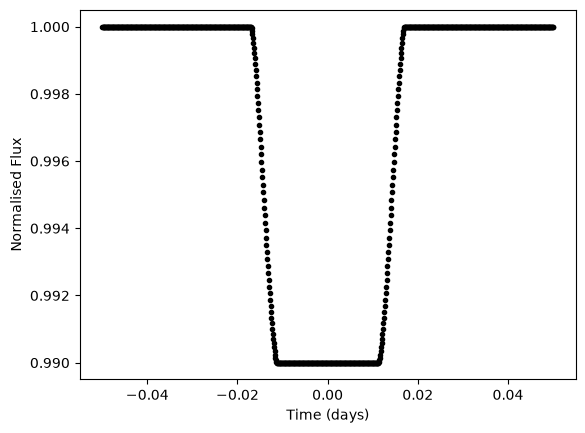

In [ ]:
# Generate 100 evenly spaced time points (in units of days)
N_t = 1000
x_t = jnp.linspace(-0.05, 0.05, N_t)

# Use some simple parameters typical of a hot Jupiter
# Note the size-1 arrays on parameters arameters which makes it easier to fit with PyMC
mfp = {
    "T0":0.,     # Central transit time
    "P":1.,      # Period (days)
    "a":8.,     # a
    "rho":0.1,            # Transit depth aka (Rp/R*)^2
    "b":0.7,
    "Foot":1.,               # Baseline flux out of transit
    "Tgrad":0.,               # Gradient in baseline flux (days^-1)
}

plt.plot(x_t, transit_no_ld(mfp, x_t), "k.")
plt.xlabel("Time (days)")
plt.ylabel("Normalised Flux")
plt.show()

Now let's choose our kernel function model. We will pick a Matern-3/2 kernel plus white noise, and we will start without utilising any optimisation as a quasiseparable kernel. This kernel is defined as:
$$
\begin{equation}
k(t, t') = \sigma^2\delta_{tt'} + h^2\left(1 + \sqrt{3} \frac{|t - t'|}{l_{t}}\right) \exp{\left(-\sqrt{3}\frac{|t - t'|}{l_{t}}\right)}\nonumber
\end{equation}
$$
where the white noise has a standard deviation of $\sigma$, the correlated noise has a height scale of $h$, and a length scale of $l_t$. We will fit for the log of these parameters, as a log-uniform prior is often a natural choice for these parameters.

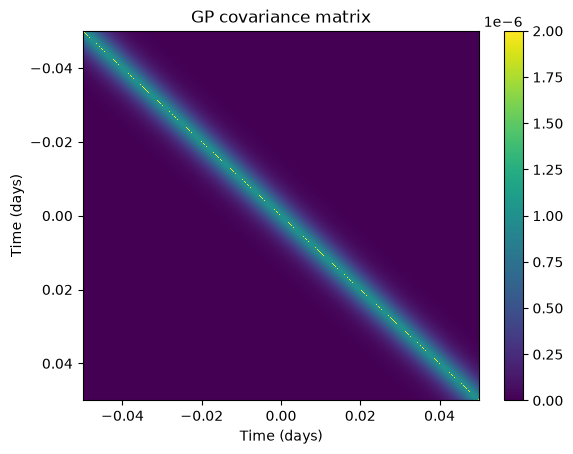

In [8]:
# We define our kernel function, also in the form of fn(par, X, *kf_args, **kf_kwargs)
def build_kf(hp, x_t):

    # Noise takes the standard deviation of the noise, not the variance
    St = luas.kernels.Noise(jnp.exp(hp["log_sigma"]))

    # We can scale kernels by a height scale, in this case make sure to square it
    Kt = jnp.exp(2*hp["log_h"]) * luas.kernels.quasisep.Matern32(jnp.exp(hp["log_l_t"]))

    # Simply return the kernel
    return St + Kt
    
hp = {
    "log_h":np.log(1e-3),
    "log_l_t":np.log(0.004),
    "log_sigma":np.log(1e-3),
}

# build the kernel object if you want to visualise it
kernel = build_kf(hp, x_t)

# we can build the full covariance matrix by calling it with its input vectors
# note this can be very memory intensive for long time-series!
K = kernel(x_t, x_t)

plt.pcolormesh(x_t, x_t, K)
plt.gca().invert_yaxis()
plt.colorbar()
plt.xlabel("Time (days)")
plt.ylabel("Time (days)")
plt.title("GP covariance matrix")
plt.show()

We can build our GP model by combining these together. We may also want to add a logPrior function if we have priors on particular parameters we want to add to our log-posterior calculation.

Expecting data array of shape (1000,) based on input vectors in X.
Using GP optimisation Quasiseparable (1D)
GP log-posterior value: 5399.788710005136


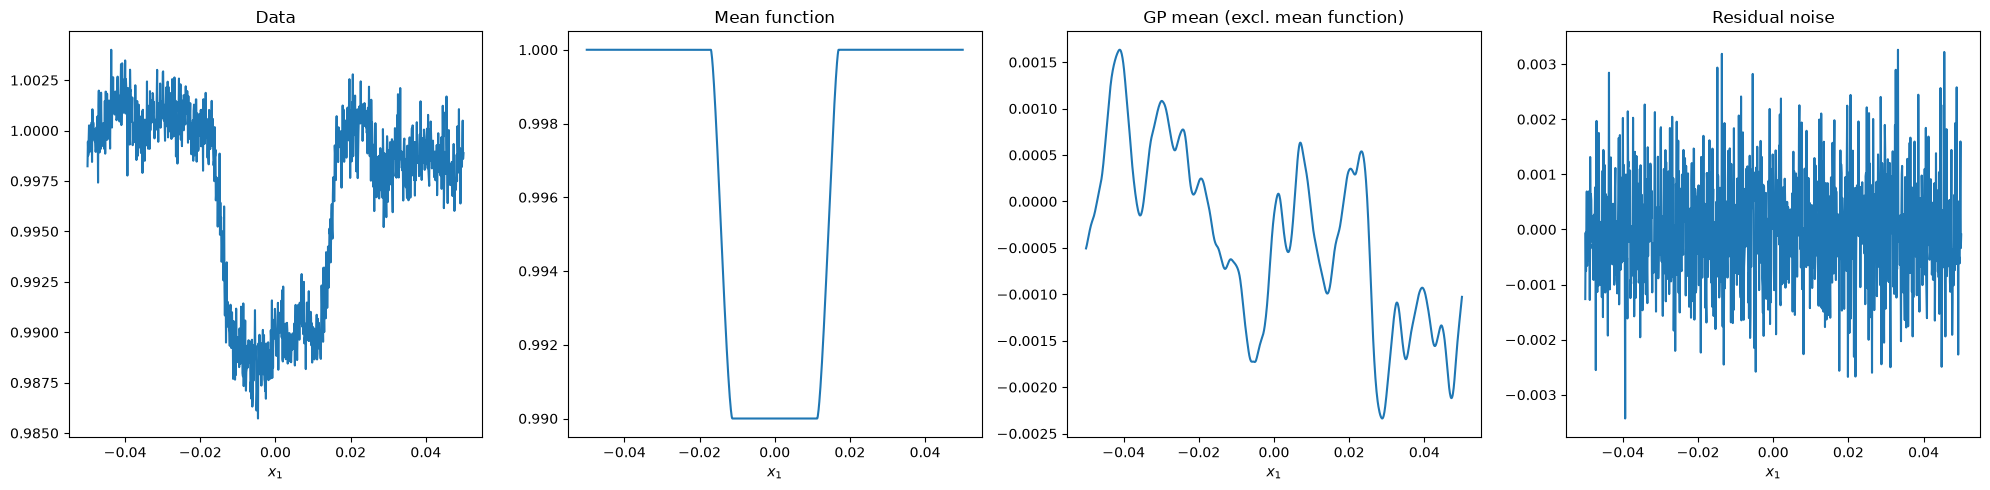

In [11]:
prior_dict = {"P":{"mean":1., "std":1e-5}}

def logPrior(p, x_t):

    # normal prior on the period
    logPrior_val = - 0.5 * (p["P"] - prior_dict["P"]["mean"])**2/prior_dict["P"]["std"]**2

    return logPrior_val


p_init = deepcopy(mfp)
p_init.update(hp)

# build our GP model
gp = luas.GP(p_init, x_t, kf = build_kf, mf = transit_no_ld, logPrior = logPrior)

# sample from the GP prior
# in this case will generate a synthetic observation with correlated noise following our kernel model
y = gp.sample(p_init)

# Visualise our GP fit to this synthetic observation
gp.plot(p_init, y, sharey = False)

print(f"GP log-posterior value: {gp.logP(p_init, y)}")

We have a simple interface to optimise a model which uses ``PyMC`` as a backend. You can specify some prior bounds on some of the parameters if you wish, as well as which parameters you would like to optimise.

Varying parameters: ['Foot', 'P', 'T0', 'Tgrad', 'a', 'b', 'log_h', 'log_l_t', 'log_sigma', 'rho']
Fixed parameters: []


Output()

GP log-posterior value: 5403.670742489444


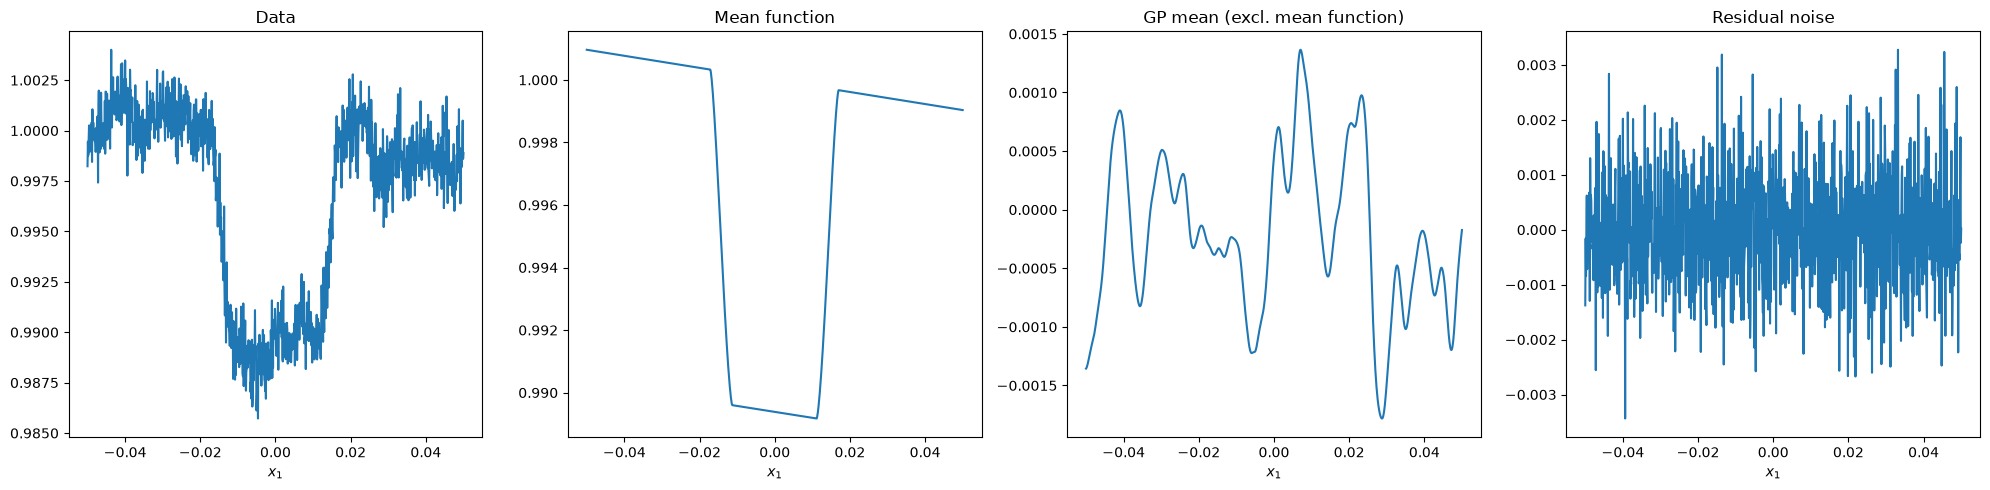

In [13]:
param_bounds = {
    "b":[0., 1.],
    "Foot":[0.999, 1.001],
    "Tgrad":[-1., 1.],
    "log_h":[-10., -5.],
    "log_l_t":[np.log(0.001), np.log(0.05)],
    "log_sigma":[-10., -5.],
}


p_opt = gp.optimise(p_init, y, param_bounds = param_bounds)


gp.plot(p_opt, y)
print(f"GP log-posterior value: {gp.logP(p_opt, y)}")

In [14]:
fixed_vars = []

# Returns the covariance matrix returned by the Laplace approximation
# within the transformed latent space used by PyMC
# Also returns a list of parameters which is the order the array is in
# This matches the way jax.flatten_util.ravel_pytree will sort the parameter PyTree into
cov_mat, ordered_param_list = gp.laplace_approx_with_bounds(
    p_opt,               # Make sure to use best-fit values
    y,             # The observations being fit
    param_bounds,        # Specify the same bounds that will be used for the MCMC
    fixed_vars = fixed_vars,  # Make sure to specify fixed parameters as otherwise they are marginalised over
    return_array = True, # May optionally return a nested PyTree if set to False which can be more readable
    regularise = True,   # Often necessary to regularise values that return negative covariance
)

Build our model again using the same parameters being varied and sample all parameters using NUTS. You may want to run more than 2 chains, each chain takes about 1 minute to run on my M1 Macbook.

PyMC appears to be unable to run JAX functions in parallel which is why ``cores = 1`` has been set. If wanting to run in parallel then the current suggestion is to run separate programs in parallel which each runs a chain with ``PyMC`` and save each ``arviz`` inference data object separately. These can later by loaded in and combined with ``arviz.concat``

In [15]:
import pymc as pm


# Initialise our PyMC model with optimised parameters
pymc_model, var_dict, p_pymc = gp.pymc_model(p_opt, y, param_bounds = param_bounds, fixed_vars = fixed_vars)

# NUTS_model_vars = [var_dict[par] for par in vars]
# steps = [pm.NUTS(NUTS_model_vars, model = pymc_model)]

# cov_mat = jnp.eye(len(vars))

NUTS_model_vars = [var_dict[par] for par in ordered_param_list]
steps = [pm.NUTS(NUTS_model_vars, model = pymc_model, scaling = cov_mat, is_cov = True)]

# Begin MCMC sampling, here just with a few samples to get started
# For a real analysis, probably want at least 4 chains and >=4000 total posterior draws
idata = pm.sample(
    model = pymc_model, # PyMC model to sample
    step = steps,       # Sampling steps to use (can be list for blocked Gibbs sampling)
    initvals = p_pymc,  # Starting point of inference (will jitter around this location)
    draws = 1000,       # Number of samples from MCMC post warm-up
    tune = 1000,        # Number of tuning steps
    chains = 2,         # Number of chains to run
    cores = 1,          # This will probably fail if not set to 1 as I don't think PyMC can parallelise JAX functions
)

# Saves the inference object
#idata.to_json(save_location);

Varying parameters: ['Foot', 'P', 'T0', 'Tgrad', 'a', 'b', 'log_h', 'log_l_t', 'log_sigma', 'rho']
Fixed parameters: []


Sequential sampling (2 chains in 1 job)
NUTS: [Foot, P, T0, Tgrad, a, b, log_h, log_l_t, log_sigma, rho]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 26 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Print a summary of the samples using ``arviz``. Important values to look at for convergence are that the effective sample size of the bulk of the distribution (``ess_bulk``) and the tail of the distribution (``ess_tail``) are at least ~500-1000 and that the Gelman-Rubin ``r_hat`` statistic is less than ~1.01 for each parameter.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
P,1.000000,0.000010,0.999982,1.000019,2.000000e-07,2.000000e-07,1929.597440,1342.396164,0.999623
T0,-0.000084,0.000176,-0.000431,0.000230,4.100000e-06,4.000000e-06,1851.970679,1314.004453,1.000775
a,8.128483,0.318408,7.525739,8.745796,8.139400e-03,7.829100e-03,1529.987225,1265.885122,1.000893
rho,0.100932,0.002755,0.095597,0.105876,6.440000e-05,7.890000e-05,1940.496281,940.164766,1.002561
Foot,0.999681,0.000295,0.999103,1.000210,9.200000e-06,8.600000e-06,939.285821,470.025426,1.001864
Tgrad,-0.019069,0.008992,-0.035991,-0.002148,2.244000e-04,3.200000e-04,1679.065923,1220.915552,1.002783
b,0.678432,0.034384,0.612411,0.743768,8.513000e-04,8.744000e-04,1622.956844,1339.745681,1.001559
log_h,-7.046392,0.220765,-7.425831,-6.637369,7.761500e-03,5.458800e-03,893.249987,1061.637486,1.001803
log_l_t,-5.562818,0.256330,-6.037155,-5.103036,8.085600e-03,6.194400e-03,1066.509710,1217.267218,1.001548
log_sigma,-6.870066,0.023716,-6.913048,-6.826251,5.691000e-04,5.391000e-04,1744.137878,1424.880631,1.003318


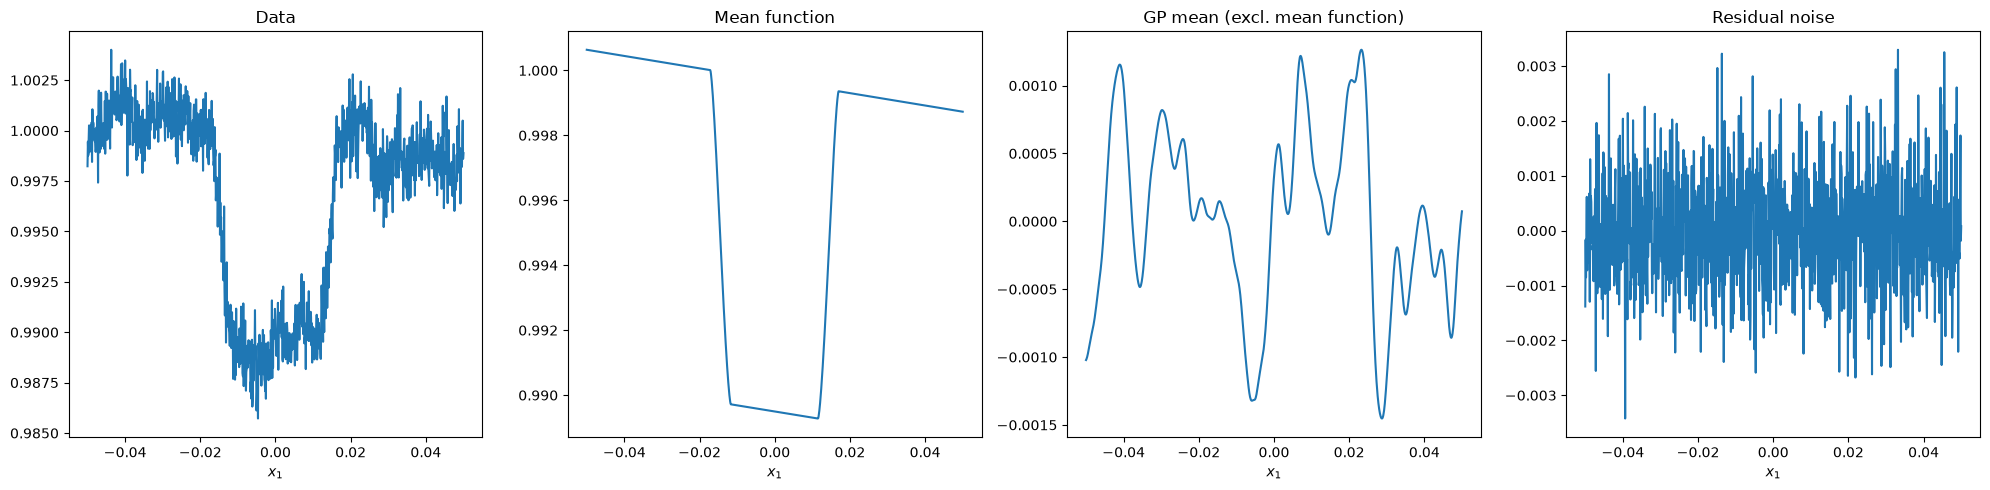

In [16]:
df_mcmc = az.summary(idata, round_to = 7)

p_mcmc = deepcopy(p_opt)

for par in df_mcmc.index:
    if "[0]" in par:
        p_mcmc[par[:-3]][:] = df_mcmc.loc[par, "mean"]
    else:
        p_mcmc[par] = df_mcmc.loc[par, "mean"]

gp.plot(p_mcmc, y)

df_mcmc

The ``arviz.plot_trace`` function can be very useful for visualising the marginal posterior distributions of the different parameters as well as to examine the chains and diagnose any possible convergence issues.

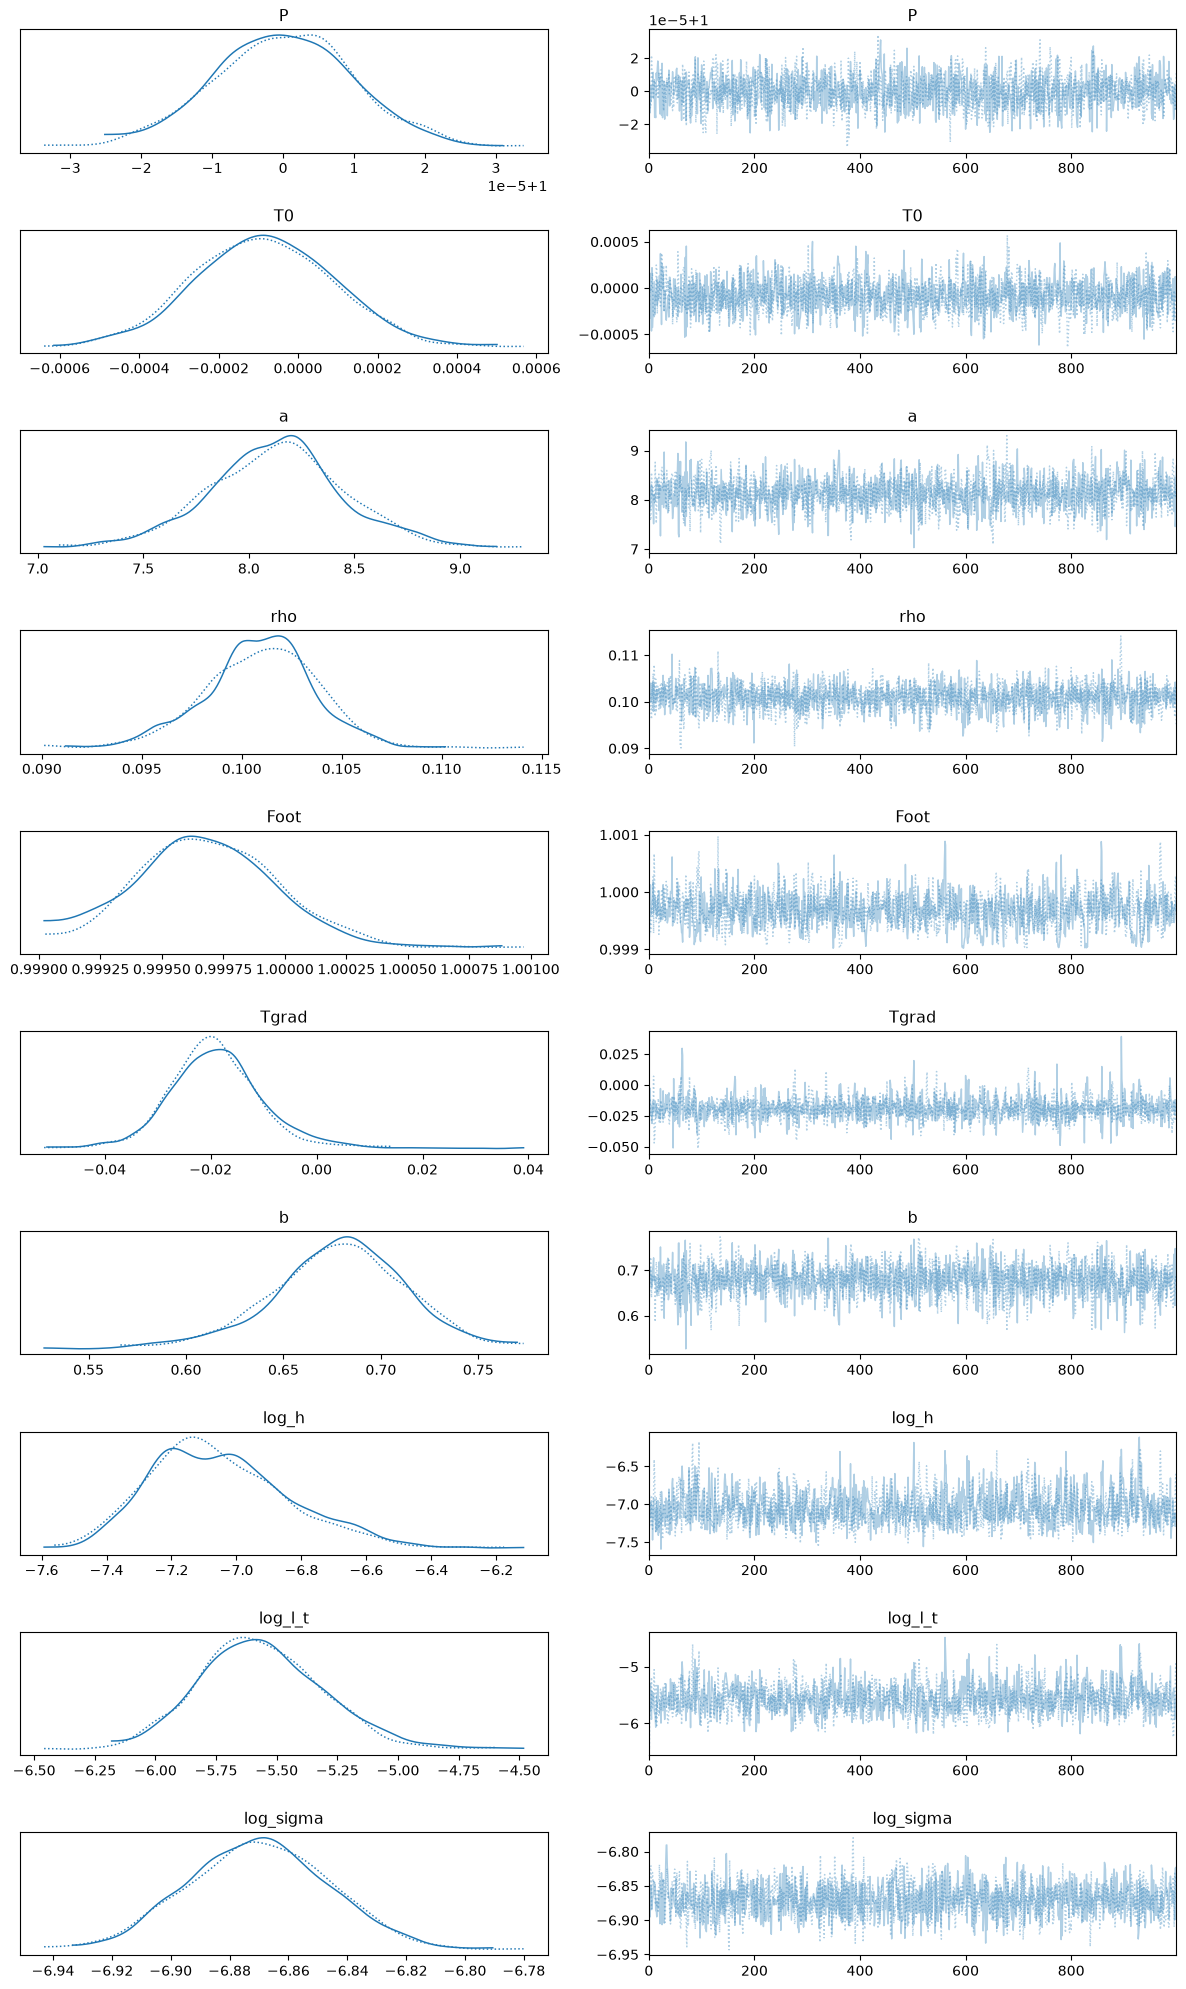

In [17]:
trace_plot = az.plot_trace(idata)
plt.tight_layout()

``corner`` is great for generating nice corner plots. Unfortunately when fitting many light curves the number of parameters can make visualising the full corner plot quite unwieldly but we can always just plot subsets of parameters instead.

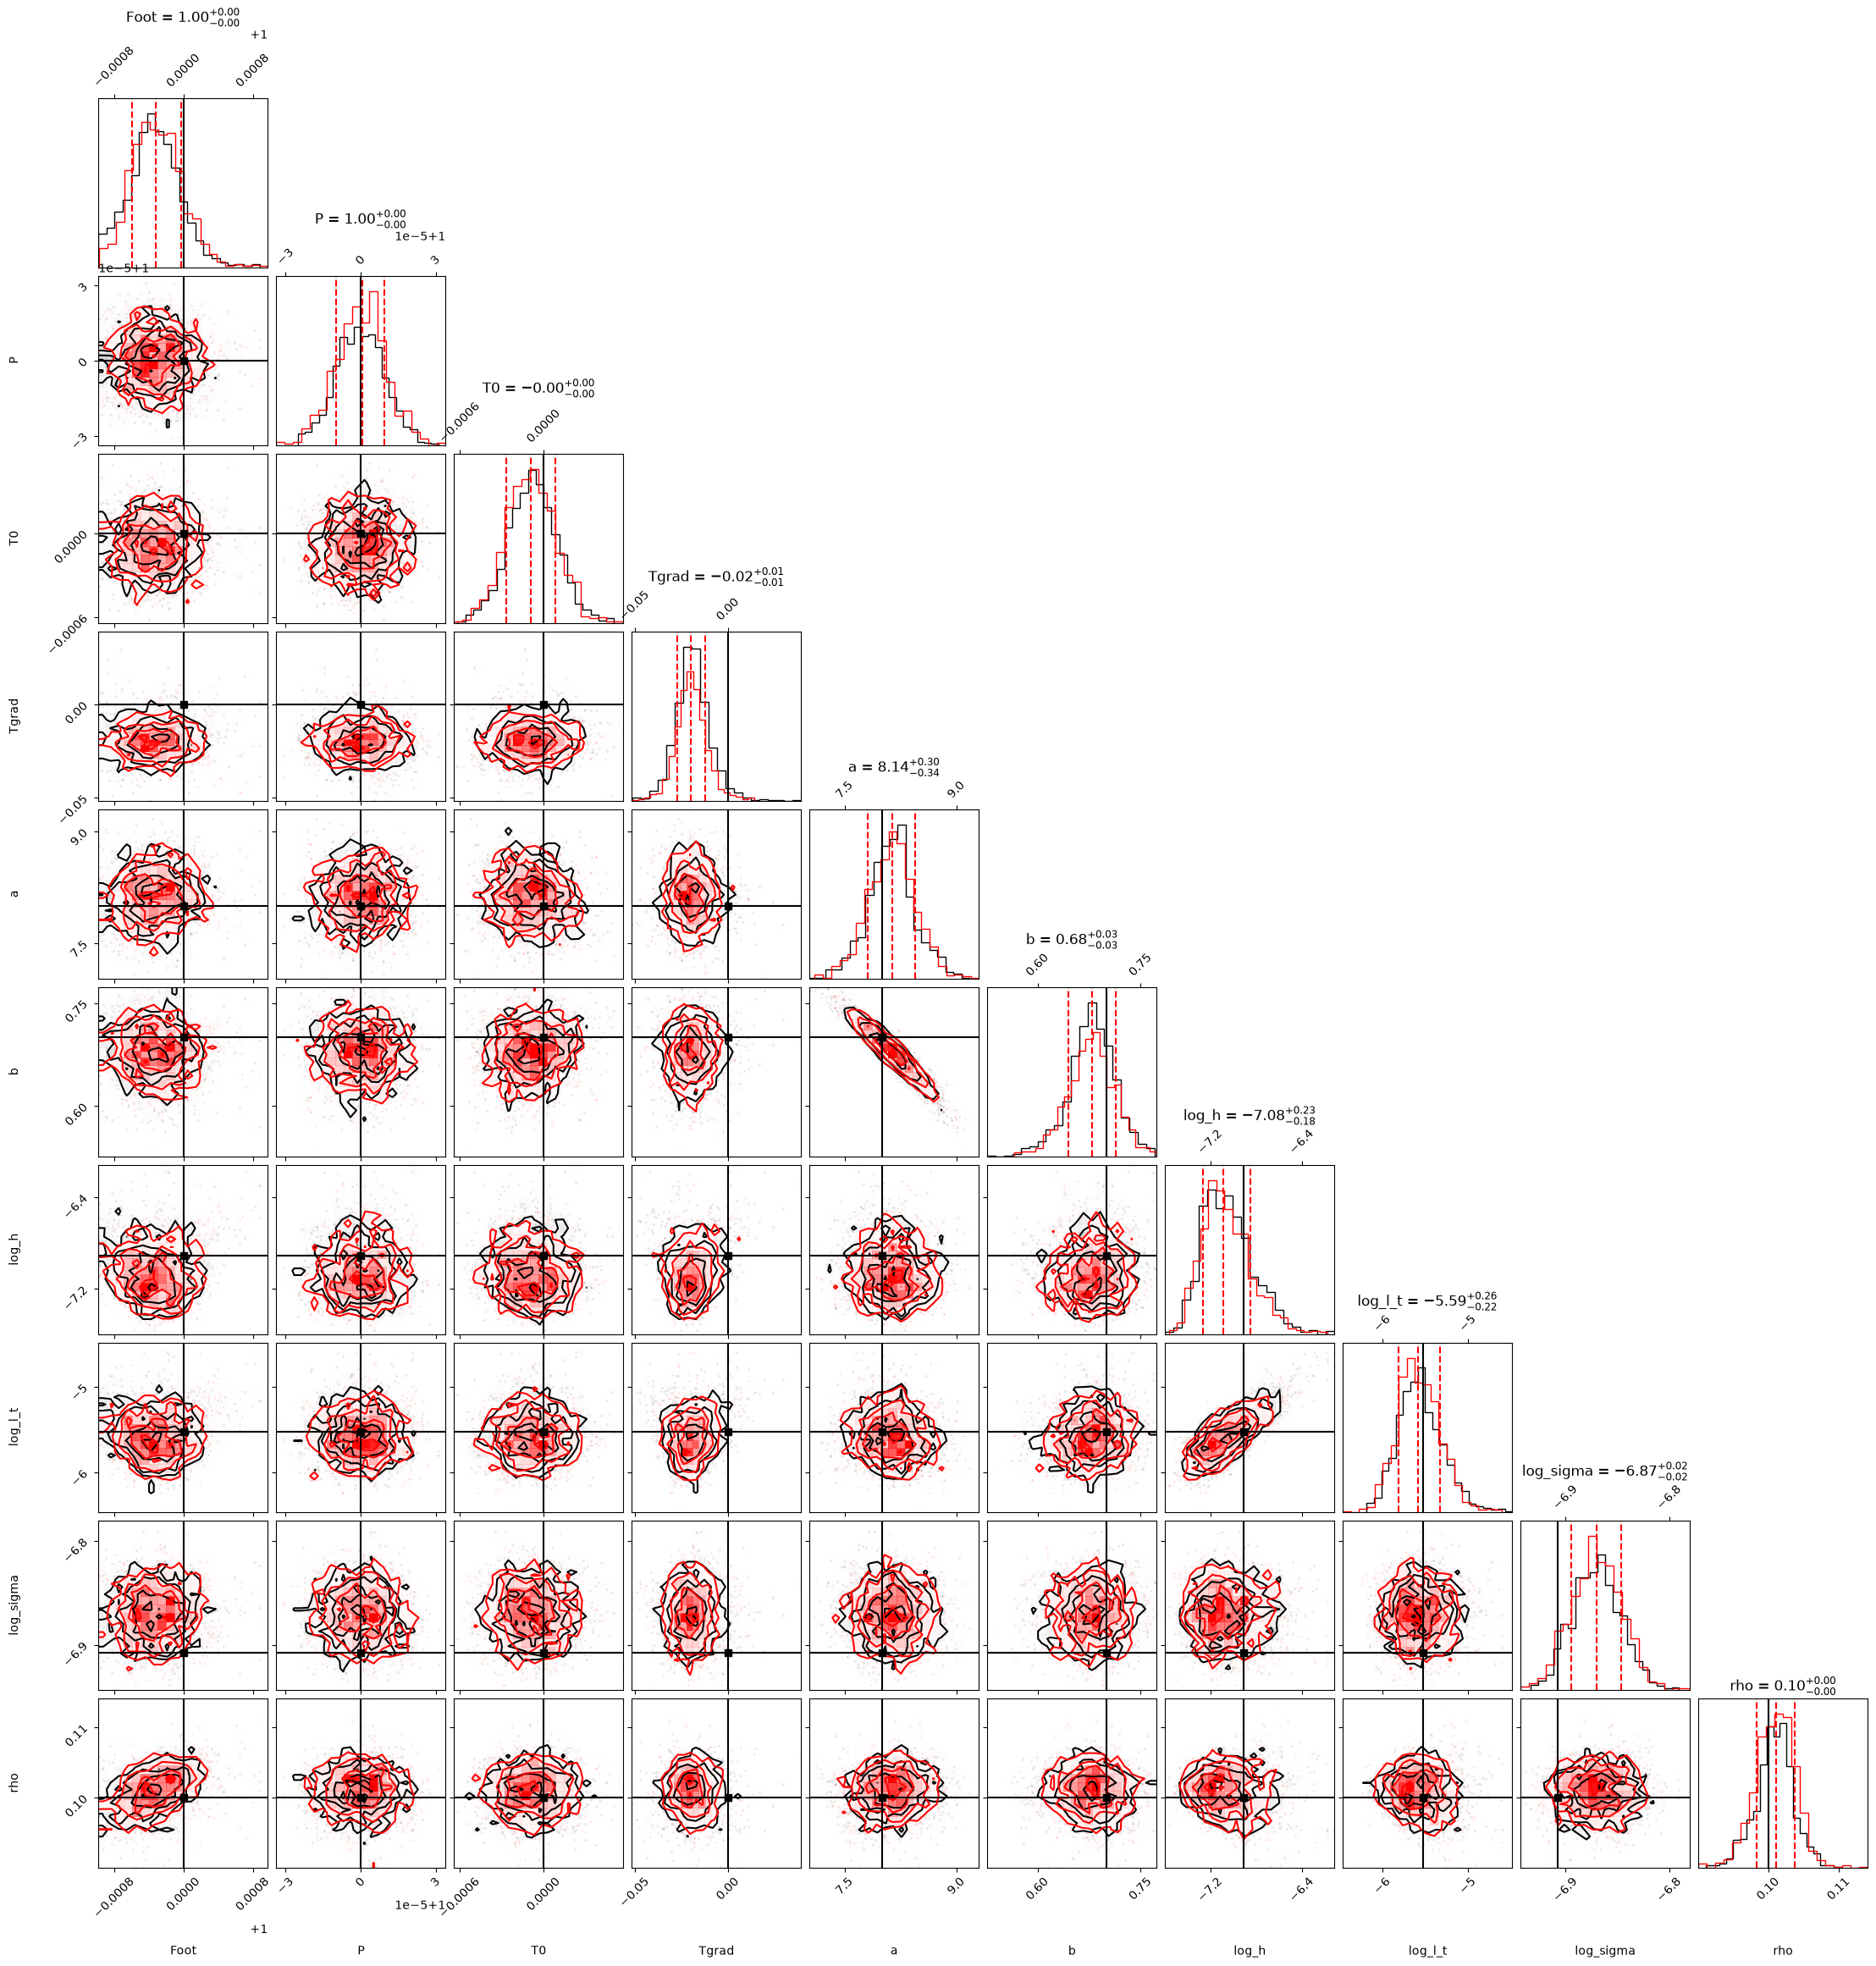

In [18]:
from corner import corner

vars = ['Foot', 'P', 'T0', 'Tgrad', 'a', 'b', 'log_h', 'log_l_t', 'log_sigma', 'rho']

# Plot each of the two chains separately
idata_corner1 = idata.sel(chain=[0])
idata_corner2 = idata.sel(chain=[1])

# Plot first chain
fig1 = corner(idata_corner1, smooth = 0.4, var_names = vars)

# Plot second chain along with truth values
fig2 = corner(idata_corner2, quantiles=[0.16, 0.5, 0.84],  show_titles=True, smooth = 0.4, color = "r", fig = fig1,
              top_ticks = True, max_n_ticks = 2, labelpad = 0.16, var_names = vars, labels = vars,
              truth_color = "k", truths = p_init,
              )